# 01. Análise exploratória das avaliações

Antes de decidir **como** construir a base de conhecimento do RAG, é preciso entender
**o que** existe nos comentários: quem escreve, quanto escreve, o que se repete, o que
está ausente e quais metadados explicam a satisfação. Cada seção termina com a decisão
técnica que ela sustenta (registro completo em `reports/decisoes_tecnicas.md`).

Base: `data/processed/reviews.parquet` (todas as avaliações) e
`data/processed/documents.parquet` (avaliações com texto), gerados por `uv run voc prepare`.

In [1]:
import json
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from voc_rag.config import REPORTS_DIR
from voc_rag.data.prepare import load_documents, load_reviews
from voc_rag.data.text import normalize_key
from voc_rag.indexing.tokenize import STOPWORDS
from voc_rag import viz

viz.aplica_estilo()
pd.set_option("display.max_colwidth", 120)

reviews = load_reviews()
docs = load_documents()
rastro = json.loads((REPORTS_DIR / "base_conhecimento.json").read_text(encoding="utf-8"))
print(f"{len(reviews):,} avaliações únicas | {len(docs):,} documentos com texto")

98,410 avaliações únicas | 42,138 documentos com texto


## 1. Do CSV à base de conhecimento

O rastro de `voc prepare` mostra o que acontece em cada etapa. Nada some sem registro.

In [2]:
etapas = pd.DataFrame([
    ("Linhas na fonte (olist_order_reviews_dataset.csv)", rastro["linhas_fonte"]),
    ("review_id ligados a mais de um pedido", rastro["review_ids_em_multiplos_pedidos"]),
    ("Avaliações únicas (uma por review_id)", rastro["avaliacoes_unicas"]),
    ("Sem mensagem na fonte", rastro["mensagem_ausente_na_fonte"]),
    ("Sem título na fonte", rastro["titulo_ausente_na_fonte"]),
    ("Mensagem sem conteúdo após limpeza (só pontuação/números)", rastro["mensagem_sem_conteudo_apos_limpeza"]),
    ("Documentos da base de conhecimento", rastro["documentos"]),
], columns=["etapa", "quantidade"])
etapas

,etapa,quantidade
0,Linhas na fonte (olist_order_reviews_dataset.csv),99224
1,review_id ligados a mais de um pedido,789
2,Avaliações únicas (uma por review_id),98410
3,Sem mensagem na fonte,57742
4,Sem título na fonte,86891
5,Mensagem sem conteúdo após limpeza (só pontuação/números),186
6,Documentos da base de conhecimento,42138


**Leitura.** Menos da metade das avaliações tem texto. As sem texto continuam na base de
avaliações (servem para estatística de nota), mas não viram documento: não há o que
recuperar nelas. A Olist liga o mesmo `review_id` a mais de um pedido; é a mesma opinião,
então conta uma vez. **Decisões D1, D2 e D3.**

## 2. Quem escreve comentário?

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


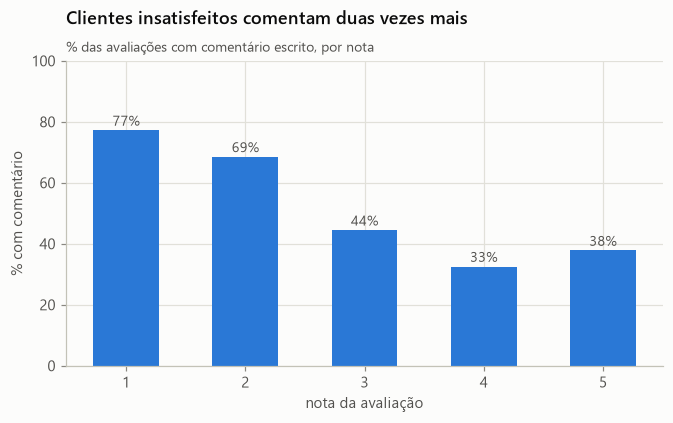

In [3]:
taxa = reviews.groupby("nota")["tem_texto"].mean().mul(100)
fig, ax = plt.subplots(figsize=(7, 3.6))
barras = ax.bar(taxa.index.astype(str), taxa.values, width=0.55, color=viz.SERIE)
viz.rotula_barras(ax, barras, "{:.0f}%")
ax.set_title("Clientes insatisfeitos comentam duas vezes mais")
viz.subtitulo(ax, "% das avaliações com comentário escrito, por nota")
ax.set_xlabel("nota da avaliação"); ax.set_ylabel("% com comentário"); ax.set_ylim(0, 100)
viz.salva(fig, "eda_comentario_por_nota"); fig

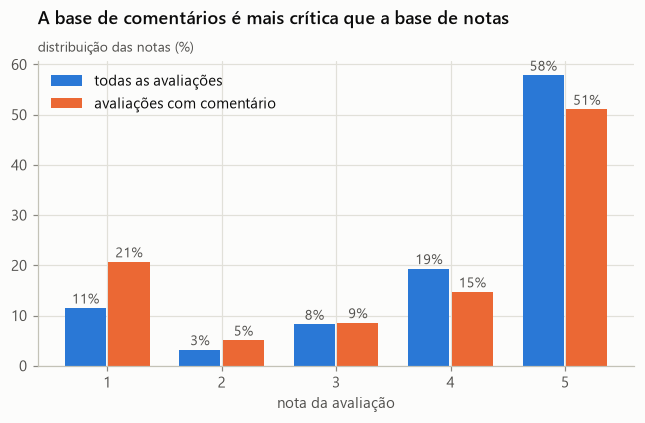

In [4]:
dist = pd.DataFrame({
    "todas as avaliações": reviews["nota"].value_counts(normalize=True).sort_index() * 100,
    "avaliações com comentário": docs["nota"].value_counts(normalize=True).sort_index() * 100,
})
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(5); w = 0.36
b1 = ax.bar(x - w / 2 - 0.01, dist.iloc[:, 0], w, label=dist.columns[0], color=viz.CATEGORICAS[0])
b2 = ax.bar(x + w / 2 + 0.01, dist.iloc[:, 1], w, label=dist.columns[1], color=viz.CATEGORICAS[1])
viz.rotula_barras(ax, b1, "{:.0f}%"); viz.rotula_barras(ax, b2, "{:.0f}%")
ax.set_xticks(x, [str(n) for n in range(1, 6)])
ax.set_title("A base de comentários é mais crítica que a base de notas")
viz.subtitulo(ax, "distribuição das notas (%)")
ax.set_xlabel("nota da avaliação"); ax.legend(loc="upper left")
viz.salva(fig, "eda_notas_base_vs_docs"); fig

**Leitura.** Quem dá nota 1 escreve comentário em cerca de 3 de cada 4 casos; quem dá 4 ou 5,
em cerca de 1 de cada 3. A nota 1 representa cerca de 11% das avaliações, mas cerca de 21%
dos comentários.

**Consequência para o RAG (D20):** qualquer frequência medida **nos comentários** descreve
quem comentou, não todos os clientes. O sistema diz isso explicitamente quando apresenta
números, e o quadro de frequências é sempre relativo ao recorte de comentários.

## 3. Tamanho dos comentários

count    42138.0
mean        11.8
std          9.8
min          1.0
50%          9.0
90%         28.0
99%         38.0
max         47.0


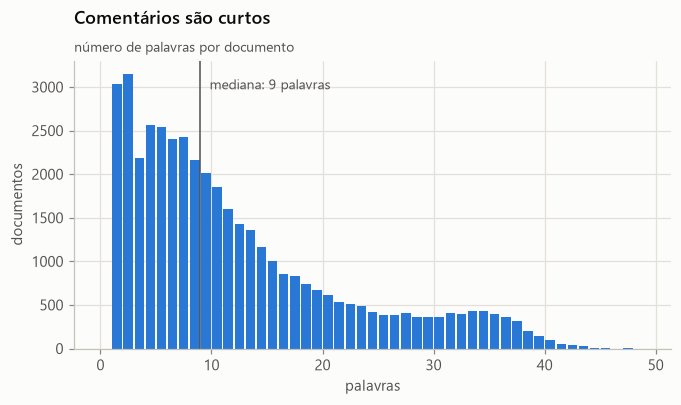

In [5]:
print(docs["n_palavras"].describe(percentiles=[.5, .9, .99]).round(1).to_string())
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(docs["n_palavras"], bins=range(0, 50), color=viz.SERIE, rwidth=0.85)
med = docs["n_palavras"].median()
ax.axvline(med, color=viz.TINTA_2, linewidth=1)
ax.annotate(f"mediana: {med:.0f} palavras", (med, ax.get_ylim()[1] * 0.9), xytext=(6, 0),
            textcoords="offset points", color=viz.TINTA_2, fontsize=9)
ax.set_title("Comentários são curtos")
viz.subtitulo(ax, "número de palavras por documento")
ax.set_xlabel("palavras"); ax.set_ylabel("documentos")
viz.salva(fig, "eda_tamanho_comentarios"); fig

**Leitura.** Nenhum comentário passa de 50 palavras (o campo da Olist é curto). Isso decide a
estratégia de documento: **uma avaliação = um documento, sem chunking** (D1). Quebrar um
texto de 10 palavras não ajuda a recuperação e destruiria a unidade natural de evidência que
o gestor quer ver citada. Também permite limitar o modelo de embedding a 256 tokens sem
truncar nada.

## 4. Textos repetidos

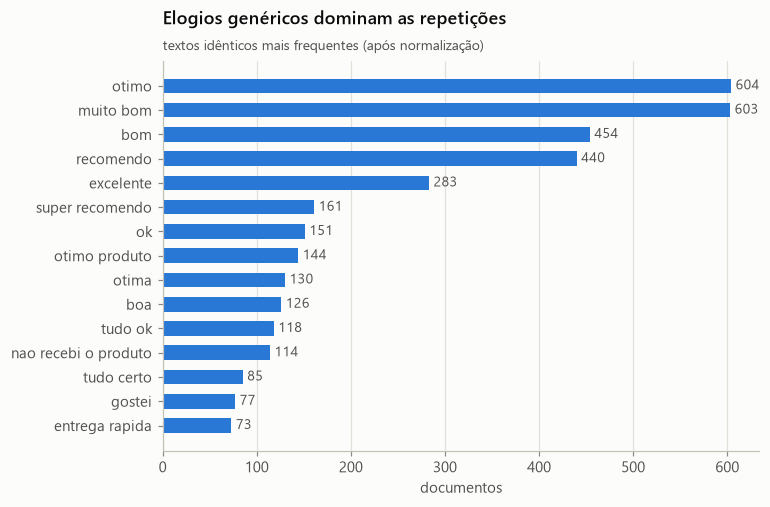

In [6]:
top = docs["texto_chave"].value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.6))
barras = ax.barh(top.index, top.values, height=0.6, color=viz.SERIE)
viz.rotula_barras(ax, barras, "{:.0f}", horizontal=True)
ax.set_title("Elogios genéricos dominam as repetições")
viz.subtitulo(ax, "textos idênticos mais frequentes (após normalização)")
ax.set_xlabel("documentos"); ax.grid(axis="y", visible=False)
viz.salva(fig, "eda_textos_repetidos"); fig

In [7]:
curtos = (docs["n_palavras"] <= 2).sum()
print(f"Documentos com texto repetido: {docs['texto_repetido'].sum():,} ({docs['texto_repetido'].mean():.1%})")
print(f"Documentos com até 2 palavras: {curtos:,} ({curtos / len(docs):.1%})")

Documentos com texto repetido: 8,426 (20.0%)
Documentos com até 2 palavras: 6,180 (14.7%)


**Leitura.** "ótimo", "muito bom", "recomendo" se repetem centenas de vezes. Cada repetição é
um cliente diferente, então **ficam no índice** (contam para frequência de satisfação geral).
Mas mandar ao LLM dez vezes "muito bom" desperdiça contexto e não acrescenta evidência:
a **deduplicação acontece na montagem do contexto**, anotando quantas vezes o texto apareceu
(D6). Note também "não recebi o produto" entre os mais repetidos: o problema de entrega
aparece até na lista de frases idênticas.

## 5. Entrega e satisfação

O metadado mais forte da base. A situação da entrega vem de `olist_orders_dataset`
(data entregue x data estimada informada ao cliente).

In [8]:
neg = reviews.groupby("entrega_status").agg(
    avaliacoes=("nota", "size"),
    pct_negativas=("nota", lambda s: (s <= 2).mean() * 100),
    nota_media=("nota", "mean"),
).loc[["no_prazo", "atrasado", "nao_entregue", "cancelado"]]
rotulos = {"no_prazo": "no prazo", "atrasado": "atrasado", "nao_entregue": "não entregue",
           "cancelado": "cancelado"}
fig, ax = plt.subplots(figsize=(7, 3.4))
barras = ax.bar([rotulos[i] for i in neg.index], neg["pct_negativas"], width=0.55, color=viz.SERIE)
viz.rotula_barras(ax, barras, "{:.0f}%")
ax.set_title("Atraso multiplica por 7 a chance de avaliação negativa")
viz.subtitulo(ax, "% de avaliações com nota 1 ou 2, por situação da entrega")
ax.set_ylim(0, 100); ax.set_ylabel("% negativas")
viz.salva(fig, "eda_entrega_negativas")
neg.round(2)

,avaliacoes,pct_negativas,nota_media
entrega_status,,,
no_prazo,89238,9.22,4.29
atrasado,6358,62.41,2.27
nao_entregue,1645,75.74,1.82
cancelado,1169,81.35,1.65


In [9]:
entregues = reviews[reviews["atraso_dias"].notna()].copy()
faixas = [-np.inf, -10, -5, 0, 3, 7, 14, 30, np.inf]
nomes = ["> 10 dias antes", "5 a 10 antes", "até 5 antes", "1 a 3 depois", "4 a 7 depois",
         "8 a 14 depois", "15 a 30 depois", "> 30 depois"]
entregues["faixa"] = pd.cut(entregues["atraso_dias"], faixas, labels=nomes, right=True)
curva = entregues.groupby("faixa", observed=True)["nota"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(len(curva)), curva["mean"], marker="o", markersize=6, color=viz.SERIE,
        markeredgecolor=viz.SUPERFICIE, markeredgewidth=2)
ax.set_xticks(range(len(curva)), curva.index, rotation=25, ha="right")
ax.axvline(2.5, color=viz.EIXO, linewidth=1)
ax.annotate("prazo estimado", (2.5, 4.5), xytext=(4, 0), textcoords="offset points",
            color=viz.TINTA_2, fontsize=9)
for i in (0, len(curva) - 1):
    ax.annotate(f"{curva['mean'].iloc[i]:.1f}", (i, curva["mean"].iloc[i]), xytext=(0, 8),
                textcoords="offset points", ha="center", color=viz.TINTA_2, fontsize=9)
ax.set_ylim(1, 5); ax.set_title("A nota despenca quando o prazo estoura")
viz.subtitulo(ax, "nota média por dias de diferença entre entrega real e prazo estimado")
ax.set_ylabel("nota média")
viz.salva(fig, "eda_atraso_nota")
curva.round(2)

,mean,size
faixa,,
> 10 dias antes,4.33,61353
5 a 10 antes,4.26,20015
até 5 antes,4.12,7870
1 a 3 depois,3.30,1842
4 a 7 depois,2.10,1742
8 a 14 depois,1.67,1441
15 a 30 depois,1.61,1006
> 30 depois,2.05,327


**Leitura.** Entregas no prazo têm cerca de 9% de avaliações negativas; atrasadas, cerca de 62%;
não entregues e canceladas passam de 75%. A nota média cai de forma contínua conforme o atraso
cresce. Entrega é o principal motor de insatisfação visível nos metadados.

**Consequência para o RAG (D7):** `entrega_status` e `atraso_dias` entram como metadados de cada
documento e como filtro ("o que dizem clientes de pedidos atrasados?"). Também aparecem no
contexto de cada evidência, para o LLM saber que aquele "demorou" veio de um pedido 12 dias
atrasado.

## 6. Categorias de produto

In [10]:
cat = docs.groupby("categoria").agg(documentos=("nota", "size"),
                                    pct_negativas=("nota", lambda s: (s <= 2).mean() * 100))
top_cat = cat.sort_values("documentos", ascending=False).head(15).sort_values("pct_negativas")
fig, ax = plt.subplots(figsize=(7.5, 5))
barras = ax.barh(top_cat.index, top_cat["pct_negativas"], height=0.6, color=viz.SERIE)
viz.rotula_barras(ax, barras, "{:.0f}%", horizontal=True)
ax.set_title("Insatisfação varia por categoria")
viz.subtitulo(ax, "% de comentários com nota 1 ou 2 nas 15 categorias com mais comentários")
ax.set_xlabel("% negativas"); ax.grid(axis="y", visible=False)
viz.salva(fig, "eda_categorias_negativas")
print(f"{docs['categoria'].nunique()} categorias; {(docs['categoria'] == 'sem_categoria').sum()} documentos sem categoria")
sem = docs[docs["categoria"] == "sem_categoria"]
print(f"Sem categoria: {sem['n_itens'].isna().sum()} pedidos sem nenhum item; situação:",
      sem["entrega_status"].value_counts().to_dict())
cat.sort_values("documentos", ascending=False).head(15).round(1)

74 categorias; 1115 documentos sem categoria
Sem categoria: 506 pedidos sem nenhum item; situação: {'no_prazo': 515, 'cancelado': 508, 'atrasado': 61, 'nao_entregue': 31}


,documentos,pct_negativas
categoria,,
cama_mesa_banho,4319,26.4
beleza_saude,3513,23.1
esporte_lazer,3013,24.6
informatica_acessorios,2783,29.4
relogios_presentes,2577,25.1
moveis_decoracao,2576,28.3
utilidades_domesticas,2462,23.2
telefonia,1883,25.7
automotivo,1750,24.7


**Leitura.** São 74 categorias, com diferenças relevantes de insatisfação entre elas. A categoria
é o metadado que permite perguntas como "o que os clientes elogiam em cama, mesa e banho?".
Pedidos com mais de um item ficam com a categoria do item de maior valor como principal, e
todas as categorias do pedido ficam registradas em `categorias`. Produtos sem categoria na
fonte viram `sem_categoria` em vez de serem descartados (D5, D7).

O grupo `sem_categoria` lidera a insatisfação por um motivo estrutural: quase metade dele são
pedidos **sem nenhum item registrado**, praticamente todos cancelados. Não é uma "categoria
ruim", é o retrato de pedidos que nunca saíram; por isso o metadado de entrega (`cancelado`)
é o filtro certo para estudá-los, não a categoria.

## 7. Período

In [11]:
mensal = docs.groupby("ano_mes").size()
mensal.index = pd.to_datetime(mensal.index.astype(str), format="%Y%m")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(mensal.index, mensal.values, color=viz.SERIE)
ax.fill_between(mensal.index, mensal.values, color=viz.SERIE, alpha=0.1, linewidth=0)
ax.set_title("Volume de comentários cresce com a operação")
viz.subtitulo(ax, "documentos por mês da compra")
ax.set_ylabel("documentos")
viz.salva(fig, "eda_volume_mensal")
docs.groupby("ano").size()

ano
2016      236
2017    18625
2018    23277
dtype: int64

**Leitura.** A base vai de 09/2016 a 10/2018, com 2016 residual. O período da compra vira o
metadado `ano_mes` (AAAAMM, inteiro), que permite filtros de intervalo direto no banco
vetorial ("reclamações de 2018").

## 8. Vocabulário: o que separa críticas de elogios

Log-odds com suavização entre bigramas de comentários negativos (nota 1 e 2) e positivos
(nota 4 e 5). Serve para conferir se a taxonomia de aspectos cobre o que os clientes de fato
escrevem.

In [12]:
def bigramas(textos):
    c = Counter()
    for t in textos:
        toks = [w for w in normalize_key(t).split() if w not in STOPWORDS and len(w) > 1]
        c.update(zip(toks, toks[1:]))
    return c

neg_c = bigramas(docs.loc[docs["nota"] <= 2, "texto"])
pos_c = bigramas(docs.loc[docs["nota"] >= 4, "texto"])
vocab = {b for b in set(neg_c) | set(pos_c) if neg_c[b] + pos_c[b] >= 40}
a, V = 0.5, len(vocab)
Nn, Np = sum(neg_c[b] for b in vocab), sum(pos_c[b] for b in vocab)
lo = {b: np.log((neg_c[b] + a) / (Nn + a * V)) - np.log((pos_c[b] + a) / (Np + a * V)) for b in vocab}
ordem = sorted(lo, key=lo.get)
tabela = pd.DataFrame({
    "típicos de críticas": [" ".join(b) for b in ordem[::-1][:15]],
    "ocorr. (crít.)": [neg_c[b] for b in ordem[::-1][:15]],
    "típicos de elogios": [" ".join(b) for b in ordem[:15]],
    "ocorr. (elog.)": [pos_c[b] for b in ordem[:15]],
})
tabela

,típicos de críticas,ocorr. (crít.),típicos de elogios,ocorr. (elog.)
0,quero produto,54,recomendo todos,290
1,propaganda enganosa,45,otimo produto,945
2,devolucao dinheiro,45,tudo perfeito,170
3,recebi nada,42,bom chegou,154
4,aguardando produto,42,amei produto,135
5,nao recomendo,448,qualidade recomendo,126
6,produto pessima,68,super recomendado,120
7,obtive resposta,56,antes esperado,119
8,nenhuma resposta,50,recomendo chegou,113
9,falta respeito,77,prazo super,112


**Leitura.** O lado das críticas é dominado por não recebimento, atraso, produto errado ou
incompleto, defeito e falta de retorno do vendedor; o dos elogios, por entrega antes do prazo,
qualidade e recomendação. É exatamente o vocabulário que a taxonomia de aspectos
(`src/voc_rag/themes/taxonomy.py`) cobre (D17). Repare que **"não"** sobrevive como token: por
isso as negações não estão na lista de stopwords do BM25 (D9).

## 9. Peculiaridades da base

In [13]:
got = docs["texto"].str.contains(r"targaryen|lannister|stark|baratheon|tyrell|martell|greyjoy",
                                 case=False, regex=True)
print(f"Comentários citando 'casas de Game of Thrones': {got.sum()}")
docs.loc[got, ["nota", "texto"]].head(5)

Comentários citando 'casas de Game of Thrones': 1955


,nota,texto
20,4,"Inicialmente o pedido veio incompleto, passei uma msg a lannister (sem receber a resposta), recebi o restante do ped..."
46,5,Tenho a loja baratheon como a minha preferencia e recomendo.
151,5,"Ótimo, não tive problema s com a compra, o stark sempre me informando a situação do produto por emails, dentro do pr..."
179,1,"As informações nos sites das lannister são irreais, dizem que os correios tiveram um imprevisto, mas em resposta qua..."
223,3,Satisfeito. Compro e sempre comprarei com Vcs d lannister.com


**Leitura.** A Olist anonimizou nomes de lojas e parceiros substituindo-os por casas de
*Game of Thrones* ("A targaryen ou as lannister?"). Não é ruído a remover: é como o dado
existe. O LLM é instruído a não inventar nomes, e esses aparecem apenas quando citados nas
evidências.

## Conclusões que viram decisões

| Achado | Decisão |
|---|---|
| Comentários de até ~50 palavras | D1: uma avaliação = um documento, sem chunking |
| 58% das avaliações sem texto | D2: só avaliações com texto viram documento; as demais ficam nas estatísticas |
| `review_id` repetido entre pedidos | D3: uma linha por `review_id` |
| Texto informal, quebras de linha, só pontuação | D4/D5: limpeza fiel ao original + chave normalizada para comparação |
| Elogios genéricos repetidos | D6: mantém no índice, deduplica no contexto |
| Entrega, categoria, período e UF explicam a satisfação | D7: metadados em cada documento e filtros na recuperação |
| Quem comenta é mais crítico | D20: frequências sempre relativas ao recorte de comentários |